In [27]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from sklearn.metrics import mean_absolute_error,mean_squared_error
from tensorflow.keras.layers import SimpleRNN, Dense

**Task 1 – Data Preparation**

In [28]:
# 1. LOAD THE DATASET
df = pd.read_csv("/content/household power consumption.csv")
df.head()

,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [29]:
# 2. CHECK THE DATASET
df.shape

(1500000, 9)

In [30]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500000 entries, 0 to 1499999
Data columns (total 9 columns):
 #   Column                 Non-Null Count    Dtype  
---  ------                 --------------    -----  
 0   Date                   1500000 non-null  object 
 1   Time                   1500000 non-null  object 
 2   Global_active_power    1500000 non-null  object 
 3   Global_reactive_power  1500000 non-null  object 
 4   Voltage                1500000 non-null  object 
 5   Global_intensity       1500000 non-null  object 
 6   Sub_metering_1         1500000 non-null  object 
 7   Sub_metering_2         1500000 non-null  object 
 8   Sub_metering_3         1491653 non-null  float64
dtypes: float64(1), object(8)
memory usage: 103.0+ MB


In [31]:
data = df["Global_active_power"]

In [32]:
# 3.Check missing values
data.isnull().sum()

np.int64(0)

In [33]:
# 4.Convert Date and Time
df['Date'] = pd.to_datetime(df['Date'] + " " + df['Time'])

/tmp/ipykernel_596/2736949130.py:2: UserWarning: Parsing dates in %d/%m/%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'] + " " + df['Time'])


In [34]:
df=df.set_index("Date")

In [35]:
df['Global_active_power'].head()

,Global_active_power
Date,
2006-12-16 17:24:00,4.216
2006-12-16 17:25:00,5.360
2006-12-16 17:26:00,5.374
2006-12-16 17:27:00,5.388
2006-12-16 17:28:00,3.666


In [36]:
# 5.Convert power consumption to numeric
#converting global_active_power to numerical data type
df['Global_active_power'] = pd.to_numeric(df['Global_active_power'], errors ='coerce')

In [37]:
# 6.Create hourly data
#creating hourly based data
hourly_data = (df['Global_active_power'].resample("h").mean())

In [38]:
hourly_data = hourly_data.dropna()
hourly_data

,Global_active_power
Date,
2006-12-16 17:00:00,4.222889
2006-12-16 18:00:00,3.632200
2006-12-16 19:00:00,3.400233
2006-12-16 20:00:00,3.268567
2006-12-16 21:00:00,3.056467
...,...
2009-10-23 05:00:00,0.654067
2009-10-23 06:00:00,1.155700
2009-10-23 07:00:00,1.395567


In [39]:
# 7.Normalize the Data
scaler = MinMaxScaler()

In [40]:
#scaling data
scaled_data = scaler.fit_transform(hourly_data.values.reshape(-1,1))
scaled_data

array([[0.63681623],
       [0.54504495],
       [0.50900588],
       ...,
       [0.19755458],
       [0.29702324],
       [0.21252382]], shape=(24871, 1))

In [41]:
# 7.Create Sequences
LOOKBACK = 24
X=[]
y=[]

In [42]:
X = []
y = []
for i in range(LOOKBACK, len(scaled_data)):
    X.append(scaled_data[i-LOOKBACK:i])
    y.append(scaled_data[i])

X = np.array(X)
y = np.array(y)

In [43]:
# 8. Train-Test Split
train_size = int(len(X)*0.8)
X_train = X[:train_size]
X_test = X[train_size:]

In [44]:
y_train = y[:train_size]
y_test = y[train_size:]

**Task 2 – RNN Model Development**

In [45]:
model = Sequential([SimpleRNN (50,activation='tanh', input_shape = (24,1)),Dense(1)])

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [46]:
# 9. COMPILE THE MODEL
model.compile(optimizer ='adam', loss='mse')

In [48]:
# 10.Train the Model
history = model.fit(
    X_train,
    y_train,
    epochs = 20,
    batch_size = 64,
    validation_split = 0.1
)

Epoch 1/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - loss: 0.0108 - val_loss: 0.0105
Epoch 2/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0097 - val_loss: 0.0106
Epoch 3/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0097 - val_loss: 0.0103
Epoch 4/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0097 - val_loss: 0.0102
Epoch 5/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - loss: 0.0097 - val_loss: 0.0105
Epoch 6/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0097 - val_loss: 0.0104
Epoch 7/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 0.0097 - val_loss: 0.0105
Epoch 8/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - loss: 0.0097 - val_loss: 0.0105
Epoch 9/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0097 - val_loss: 0.0110
Epoch 10/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0096 - val_loss: 0.0104
Epoch 11/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - loss: 0.0097 - val_loss: 0.0103
Epoch 12/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/ste

In [49]:
# 11.Evaluate the Model
predictions = model.predict(X_test)

156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [50]:
predictions = scaler.inverse_transform(predictions)
predictions

array([[1.1630623],
       [1.0993829],
       [0.8160952],
       ...,
       [1.4153324],
       [1.4395933],
       [1.743294 ]], shape=(4970, 1), dtype=float32)

In [51]:
# 12. MODEL EVALUATION
actual = scaler.inverse_transform(y_test.reshape(-1,1))
mae = mean_absolute_error(actual,predictions)
rmse = np.sqrt(mean_squared_error(actual,predictions))
print(mae)
print(rmse)

0.3494808606848453
0.5094203257356629


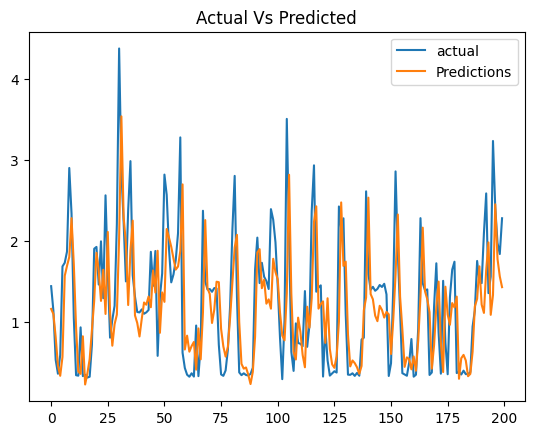

In [52]:
# 13. Actual vs Predicted
plt.plot(actual[:200],label = "actual")
plt.plot(predictions[:200],label = "Predictions")
plt.title("Actual Vs Predicted")
plt.legend()
plt.show()

In [53]:
# 14. Predict the Next Hour
last_24_hours = scaled_data[-24:]
X_new = last_24_hours.reshape(1,24,1)
next_hour_prediction = model.predict(X_new)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step


In [54]:
next_hour_prediction = scaler.inverse_transform(next_hour_prediction)
next_hour_prediction

array([[1.1985643]], dtype=float32)

**Task 3 – LSTM Model Development**

In [55]:
from tensorflow.keras.layers import LSTM, Dense

In [57]:
# BUILD LSTM MODEL

lstm_model = Sequential([
LSTM(50,activation="tanh",input_shape=(LOOKBACK, 1)),Dense(1)])
lstm_model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [58]:
# Compile the Model
lstm_model.compile(
    optimizer="adam",
    loss="mse"
)


In [59]:
# Train the LSTM
lstm_history = lstm_model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 7s 20ms/step - loss: 0.0148 - val_loss: 0.0112
Epoch 2/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 6s 21ms/step - loss: 0.0105 - val_loss: 0.0114
Epoch 3/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0101 - val_loss: 0.0112
Epoch 4/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - loss: 0.0100 - val_loss: 0.0105
Epoch 5/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0097 - val_loss: 0.0102
Epoch 6/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0096 - val_loss: 0.0100
Epoch 7/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 6s 22ms/step - loss: 0.0094 - val_loss: 0.0101
Epoch 8/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0093 - val_loss: 0.0100
Epoch 9/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step - loss: 0.0093 - val_loss: 0.0099
Epoch 10/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - loss: 0.0093 - val_loss: 0.0099
Epoch 11/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 5s 18ms/step - loss: 0.0093 - val_loss: 0.0098
Epoch 12/20
280/280 ━━━━━━━━━━━━━━━━━━━━ 

 **Task 4 – Model Evaluation**

In [60]:
# Make Predictions
lstm_predictions = lstm_model.predict(X_test)
lstm_predictions = scaler.inverse_transform(lstm_predictions)
actual = scaler.inverse_transform(y_test.reshape(-1, 1))

156/156 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step


In [61]:
# Calculate MAE and RMSE
lstm_mae = mean_absolute_error(actual,lstm_predictions)
lstm_rmse = np.sqrt(mean_squared_error(actual,lstm_predictions))
print(f"MAE  : {lstm_mae:.4f}")
print(f"RMSE : {lstm_rmse:.4f}")

MAE  : 0.3505
RMSE : 0.4972


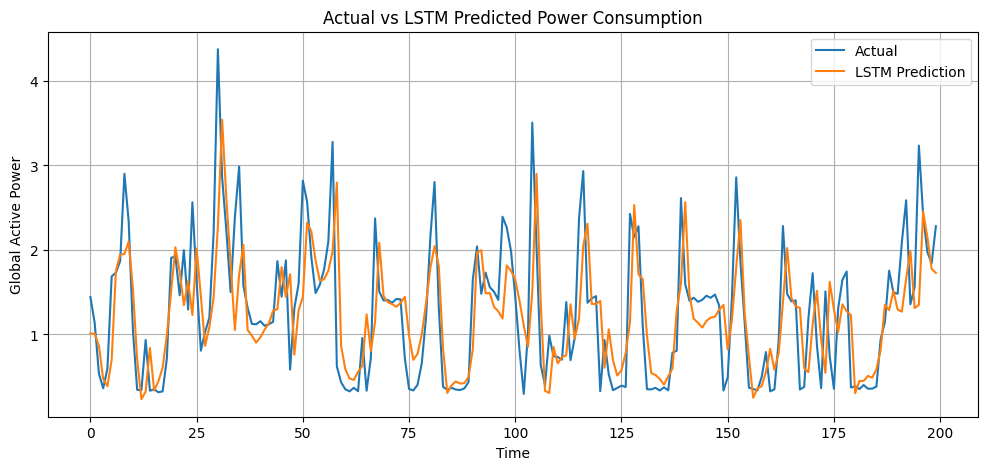

In [62]:
plt.figure(figsize=(12, 5))

plt.plot(actual[:200], label="Actual")
plt.plot(lstm_predictions[:200], label="LSTM Prediction")

plt.title("Actual vs LSTM Predicted Power Consumption")
plt.xlabel("Time")
plt.ylabel("Global Active Power")
plt.legend()
plt.grid(True)
plt.show()

**Task-5 Performance Analysis Compare RNN and LSTM performance and discuss the impact of the vanishing gradient problem**

In [63]:
comparison = pd.DataFrame({
    "Model": ["Simple RNN", "LSTM"],
    "MAE": [mae, lstm_mae],
    "RMSE": [rmse, lstm_rmse]
})

print(comparison)

        Model       MAE      RMSE
0  Simple RNN  0.349481  0.509420
1        LSTM  0.350497  0.497225


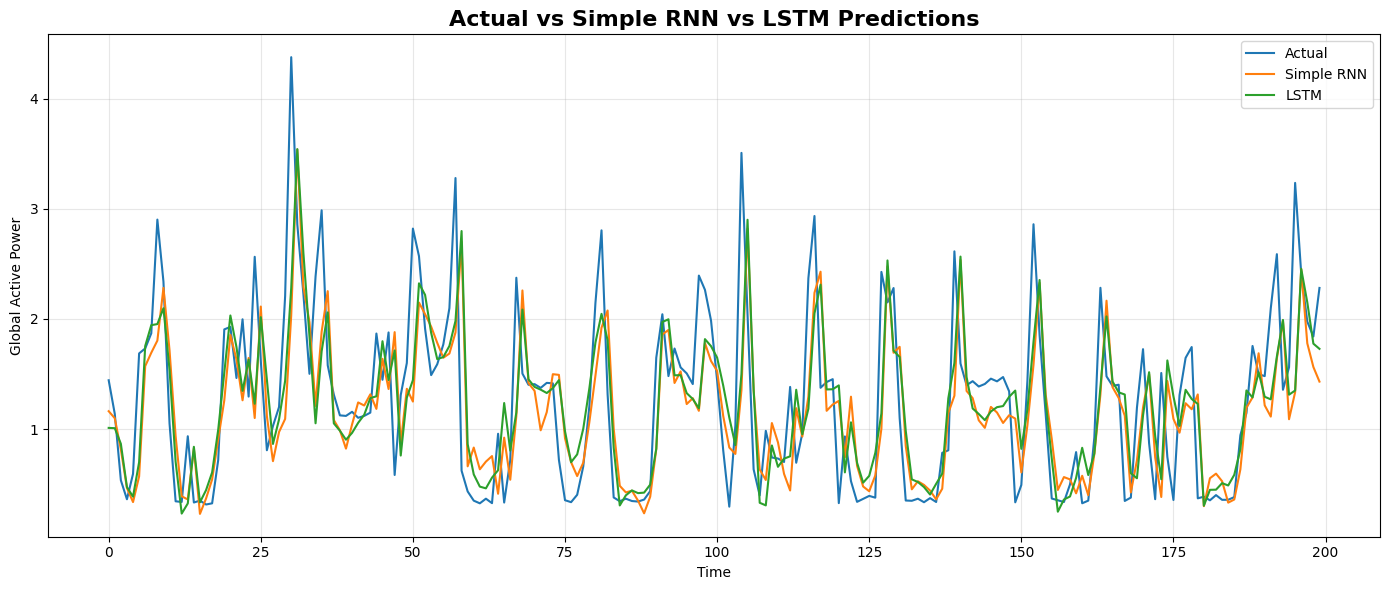

In [64]:
# Visual Comparison
plt.figure(figsize=(14, 6))

plt.plot(
    actual[:200],
    label="Actual"
)

plt.plot(
    predictions[:200],
    label="Simple RNN"
)

plt.plot(
    lstm_predictions[:200],
    label="LSTM"
)

plt.title(
    "Actual vs Simple RNN vs LSTM Predictions",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Time")
plt.ylabel("Global Active Power")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()